# Week 9 — Privacy Mechanisms in Federated SMS Spam Detection
**Theory and Applications of Federated Learning**  
**Faranak Solat · Department of AI & Data Science · Sejong University**

### Research question
How do client-update clipping and Gaussian noise change the utility of a federated spam classifier?

Open this notebook in Google Colab using **File → Upload notebook**, select a **CPU** runtime, and choose **Runtime → Run all**. No GPU or account tokens are needed. The first run downloads the public UCI SMS Spam Collection. If the download fails, upload the dataset ZIP as `sms_spam.zip` into Colab's working directory and rerun.

This is a single-process classroom simulation. The centrally loaded public dataset is partitioned into synthetic clients; it does **not** establish real user boundaries or implement a distributed deployment. All explanations, tasks, and code comments are in English.

**Learning outcomes:** implement FedAvg, clip whole-client updates, add noise to an aggregate, compare validation utility, and distinguish a noise experiment from a formal differential-privacy guarantee.

**Suggested lesson:** 10 min problem and data, 15 min implementation, 15 min experiments, 10 min discussion.

## 1. Scope and threat model
A trusted server coordinates simulated clients and releases a classifier. We study limiting the effect of a client's update on that classifier. The server can see individual updates in this implementation: **secure aggregation is not implemented**, and this is not local DP.

We compare:
1. **FedAvg:** average the client updates.
2. **Clipped FedAvg:** bound each client's entire parameter update, including its intercept.
3. **Clipping + Gaussian noise:** perturb the mean of clipped updates.

The noise multiplier is **not epsilon**. This notebook does not compute a privacy budget or claim an end-to-end DP guarantee. Fixed random seeds, per-client diagnostics, and repeated validation queries are appropriate only for this public-data teaching simulation. Production privacy would require a precise adjacency definition, a validated accountant, protected diagnostics, suitable randomness, and accounting for every released result.

In [ ]:
import io, zipfile, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix

SEED = 42
print("CPU-only simulation; NumPy", np.__version__)

CPU-only simulation; NumPy 2.1.3


## 2. Public data and leakage-resistant splitting
The UCI dataset labels messages as `ham` or `spam`. We remove duplicate normalized texts **before** splitting, keeping duplicate messages out of different splits. Messages with conflicting labels after normalization are discarded.

The split is 60% training, 20% validation, and 20% test. Model selection and learning curves use validation data. The final test set is used only after choosing a model using validation F1.

We use a fixed hashing representation instead of fitting a vocabulary on pooled client texts. Hash collisions are possible, and this simple representation is a teaching choice rather than a claim of state-of-the-art performance.

In [ ]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
archive = Path("sms_spam.zip")
if not archive.exists():
    with urllib.request.urlopen(DATA_URL, timeout=60) as response:
        archive.write_bytes(response.read())
with zipfile.ZipFile(archive) as z:
    raw = z.read("SMSSpamCollection").decode("utf-8")
rows = [line.split("\t", 1) for line in raw.splitlines() if "\t" in line]
df = pd.DataFrame(rows, columns=["label", "text"])
assert set(df.label) == {"ham", "spam"}
df["normalized"] = df.text.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
conflicts = df.groupby("normalized").label.nunique()
df = df[~df.normalized.isin(conflicts[conflicts > 1].index)]
df = df.drop_duplicates("normalized").reset_index(drop=True)
y = (df.label == "spam").astype(int).to_numpy()
indices = np.arange(len(df))
train_idx, hold_idx = train_test_split(indices, test_size=0.4, stratify=y, random_state=SEED)
val_idx, test_idx = train_test_split(hold_idx, test_size=0.5, stratify=y[hold_idx], random_state=SEED)
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx) or set(val_idx) & set(test_idx))
vectorizer = HashingVectorizer(n_features=2048, alternate_sign=False, norm="l2", lowercase=True)
X = vectorizer.transform(df.text).astype(np.float64)
X_train, X_val, X_test = X[train_idx], X[val_idx], X[test_idx]
y_train, y_val, y_test = y[train_idx], y[val_idx], y[test_idx]
print(f"Unique messages: {len(df)}; train={len(train_idx)}, validation={len(val_idx)}, test={len(test_idx)}")
print(f"Training spam fraction: {y_train.mean():.3f}")

Unique messages: 5159; train=3095, validation=1032, test=1032
Training spam fraction: 0.124


## 3. Simulate heterogeneous clients
We partition training examples using a class-wise Dirichlet distribution. This induces differences in local spam prevalence and dataset size. These clients are **synthetic**, not identified real senders or users. We retry only to avoid near-empty clients, so the result is a constrained Dirichlet split.

Every client participates in every round. Aggregation weights each client equally, corresponding to an average of client objectives. With unequal dataset sizes this differs from sample-weighted FedAvg. All experimental conditions use the same fixed partition.

 client  messages  spam_fraction
      0       101       0.148515
      1        23       0.086957
      2       125       0.144000
      3        53       0.113208
      4       167       0.520958
      5       177       0.073446
      6       197       0.126904
      7        62       0.016129
      8        48       0.041667
      9        74       0.405405
     10        76       0.118421
     11       318       0.119497
     12        98       0.030612
     13       296       0.027027
     14       608       0.021382
     15        69       0.405797
     16       113       0.017699
     17       203       0.374384
     18       179       0.022346
     19       108       0.046296


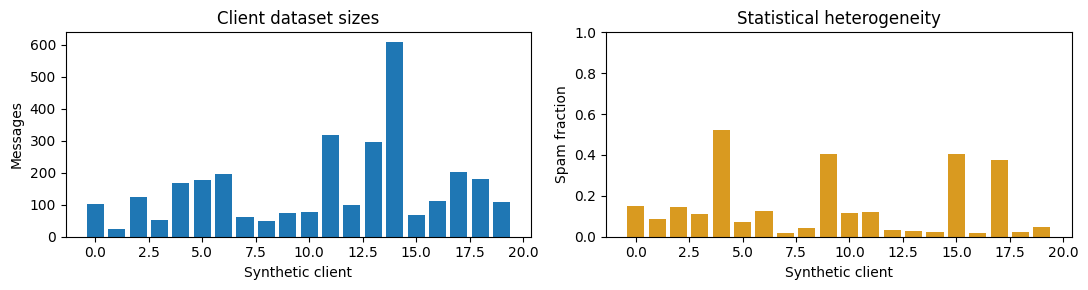

In [ ]:
def partition_clients(labels, n_clients=20, alpha=0.7, seed=SEED):
    rng = np.random.default_rng(seed)
    for attempt in range(1000):
        parts = [[] for _ in range(n_clients)]
        for label in np.unique(labels):
            idx = np.flatnonzero(labels == label)
            rng.shuffle(idx)
            proportions = rng.dirichlet(np.full(n_clients, alpha))
            cuts = (np.cumsum(proportions)[:-1] * len(idx)).astype(int)
            for k, chunk in enumerate(np.split(idx, cuts)):
                parts[k].extend(chunk.tolist())
        if min(map(len, parts)) >= 15:
            return [np.array(part, dtype=int) for part in parts]
    raise RuntimeError("Could not obtain a valid partition; increase alpha.")

parts = partition_clients(y_train)
assert np.array_equal(np.sort(np.concatenate(parts)), np.arange(len(y_train)))
clients = [(X_train[idx], y_train[idx]) for idx in parts]
client_summary = pd.DataFrame({"client": np.arange(len(parts)), "messages": [len(x) for x in parts],
                              "spam_fraction": [y_train[x].mean() for x in parts]})
print(client_summary.to_string(index=False))
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].bar(client_summary.client, client_summary.messages)
axes[0].set(title="Client dataset sizes", xlabel="Synthetic client", ylabel="Messages")
axes[1].bar(client_summary.client, client_summary.spam_fraction, color="#d99a20")
axes[1].set(title="Statistical heterogeneity", xlabel="Synthetic client", ylabel="Spam fraction", ylim=(0,1))
plt.tight_layout(); plt.show()

## 4. Model and local optimization
The model is logistic regression: $p(y=1\mid x)=\operatorname{sigmoid}(x^T w+b)$.

Clients minimize a weighted binary cross-entropy objective with a small L2 penalty on $w$. Spam has a fixed weight of 3 to address class imbalance. The intercept is not regularized. This weight is chosen in advance and is identical in every condition.

Each round starts every client from the current global vector $\theta_t=[w_t;b_t]$. The client performs a fixed number of full-batch gradient steps and returns $u_k=\theta_k-\theta_t$. The server never receives raw messages in the simulated update interface, although all data reside in one process for convenience.

In [ ]:
ROUNDS = 50
LOCAL_STEPS = 5
LEARNING_RATE = 1.0
L2 = 1e-3
SPAM_WEIGHT = 3.0
CLIP_NORM = 0.30  # Prespecified classroom setting, not tuned on the test set.

In [ ]:
def local_update(theta, features, labels):
    local = theta.copy()
    weights = np.where(labels == 1, SPAM_WEIGHT, 1.0)
    for _ in range(LOCAL_STEPS):
        probabilities = expit(features @ local[:-1] + local[-1])
        residual = weights * (probabilities - labels)
        grad_w = np.asarray(features.T @ residual).ravel() / len(labels) + L2 * local[:-1]
        grad_b = residual.mean()
        local[:-1] -= LEARNING_RATE * grad_w
        local[-1] -= LEARNING_RATE * grad_b
    return local - theta

def clip_updates(updates, bound):
    if bound <= 0:
        raise ValueError("The clipping bound must be positive.")
    norms = np.linalg.norm(updates, axis=1)
    factors = np.minimum(1.0, bound / np.maximum(norms, 1e-12))
    return updates * factors[:, None], norms

def evaluate(theta, features, labels):
    prediction = (expit(features @ theta[:-1] + theta[-1]) >= 0.5).astype(int)
    return {"f1": f1_score(labels, prediction, zero_division=0),
            "precision": precision_score(labels, prediction, zero_division=0),
            "recall": recall_score(labels, prediction, zero_division=0),
            "accuracy": accuracy_score(labels, prediction)}

## 5. Clipping and Gaussian noise
Clip each whole update to an L2 radius $C$:

$$\bar u_k=u_k\min\left(1,\frac{C}{\|u_k\|_2}\right).$$

The server update is

$$\theta_{t+1}=\theta_t+\frac{1}{K}\sum_{k=1}^K\bar u_k+z_t,\qquad z_t\sim\mathcal N(0,s^2 I).$$

For a **fixed roster of K clients** and replacement of one client's entire dataset, the mean of clipped updates has an L2 sensitivity bound of $2C/K$, conditional on a fixed incoming model. We set $s=\text{noise multiplier}\times 2C/K$ in this illustration. The intercept is included in clipping and noise.

A sensitivity bound and Gaussian noise do not by themselves constitute a complete privacy analysis: releases across rounds must be composed. No sampling amplification is claimed because every client participates. Changing the roster or adjacency definition requires revisiting the sensitivity. The data-dependent partition and diagnostic displays here are outside a formal privacy pipeline.

In [ ]:
def train_federated(clip=None, noise_multiplier=0.0, seed=SEED, rounds=ROUNDS):
    if noise_multiplier < 0 or (noise_multiplier > 0 and clip is None):
        raise ValueError("Noise must be nonnegative and requires a clipping bound.")
    rng = np.random.default_rng(seed)  # Reproducible teaching experiment, not secure randomness.
    theta = np.zeros(X_train.shape[1] + 1)
    history = []
    first_round = None
    for round_id in range(rounds):
        updates = np.vstack([local_update(theta, a, b) for a, b in clients])
        original_norms = np.linalg.norm(updates, axis=1)
        released = updates if clip is None else clip_updates(updates, clip)[0]
        if first_round is None:
            first_round = (original_norms.copy(), np.linalg.norm(released, axis=1))
        mean_update = released.mean(axis=0)
        noise_std = 0.0 if clip is None else noise_multiplier * 2 * clip / len(clients)
        noise = rng.normal(0, noise_std, size=theta.shape)
        theta += mean_update + noise
        metrics = evaluate(theta, X_val, y_val)
        history.append({"round": round_id + 1, **metrics,
                        "mean_update_norm": np.linalg.norm(mean_update),
                        "noise_norm": np.linalg.norm(noise),
                        "clipped_fraction": 0.0 if clip is None else np.mean(original_norms > clip)})
    return {"theta": theta, "history": pd.DataFrame(history), "first_round": first_round}

# Mechanism checks: zero vectors, radius bound, no clipping below the bound.
example = np.array([[3.0, 4.0], [0.0, 0.0], [0.1, 0.1]])
bounded, _ = clip_updates(example, 1.0)
assert np.all(np.linalg.norm(bounded, axis=1) <= 1.0 + 1e-12)
assert np.allclose(bounded[0], [0.6, 0.8])
assert np.allclose(bounded[1:], example[1:])
a = train_federated(rounds=1)
b = train_federated(clip=1e6, rounds=1)
assert np.allclose(a["theta"], b["theta"])
print("Mechanism checks passed.")

Mechanism checks passed.


## 6. Controlled comparison
We keep the partition, initialization, local optimizer, number of rounds, threshold, and client weighting fixed. Only clipping and noise change. The third condition uses a noise multiplier of 0.5 as an illustrative setting, not as a privacy budget.

The positive-class F1 score is the main utility metric. Accuracy alone can obscure poor spam detection because ham is the majority class.

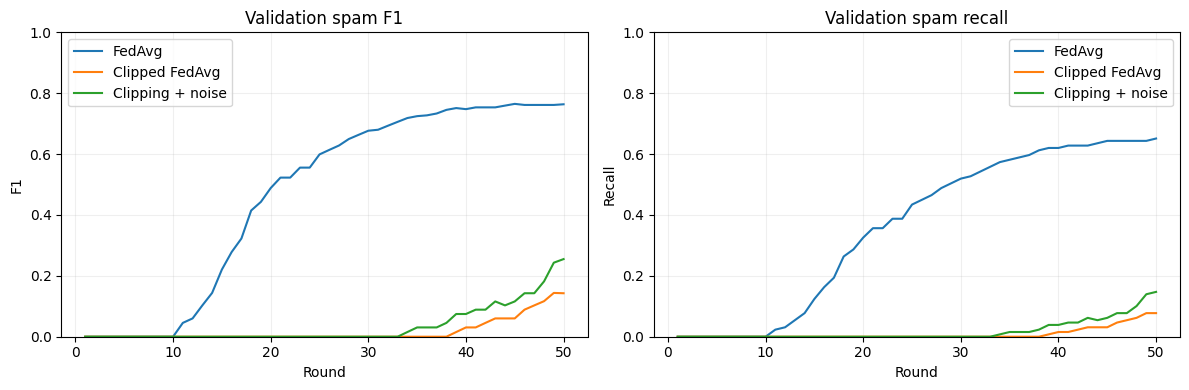

                      f1  precision  recall  accuracy
FedAvg            0.7636     0.9231  0.6512    0.9496
Clipped FedAvg    0.1429     0.9091  0.0775    0.8837
Clipping + noise  0.2550     0.9500  0.1473    0.8924


In [ ]:
settings = {"FedAvg": (None, 0.0), "Clipped FedAvg": (CLIP_NORM, 0.0),
            "Clipping + noise": (CLIP_NORM, 0.5)}
results = {name: train_federated(clip=c, noise_multiplier=s) for name, (c, s) in settings.items()}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, result in results.items():
    h = result["history"]
    axes[0].plot(h["round"], h.f1, label=name)
    axes[1].plot(h["round"], h.recall, label=name)
axes[0].set(title="Validation spam F1", xlabel="Round", ylabel="F1", ylim=(0,1))
axes[1].set(title="Validation spam recall", xlabel="Round", ylabel="Recall", ylim=(0,1))
for ax in axes: ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()
summary = pd.DataFrame({name: evaluate(r["theta"], X_val, y_val) for name, r in results.items()}).T
print(summary.round(4).to_string())

## 7. Did clipping operate as intended?
Compare the first-round client-update norms before and after clipping. Later, updates may become small enough that clipping rarely activates. This is a useful mechanism check rather than evidence of privacy.

In a real private system, these per-client diagnostics could themselves leak information. They are displayed here only because the teaching dataset is public.

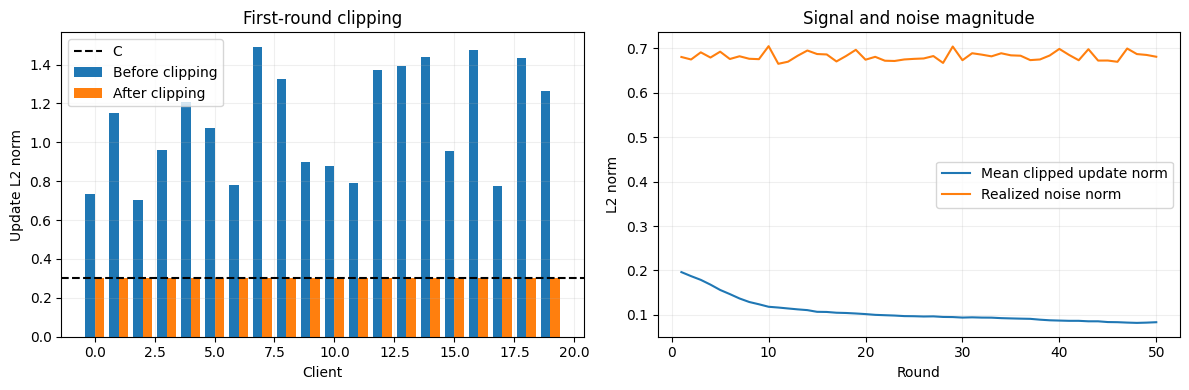

In [ ]:
before, after = results["Clipped FedAvg"]["first_round"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(before))
axes[0].bar(x - 0.2, before, 0.4, label="Before clipping")
axes[0].bar(x + 0.2, after, 0.4, label="After clipping")
axes[0].axhline(CLIP_NORM, color="black", linestyle="--", label="C")
axes[0].set(xlabel="Client", ylabel="Update L2 norm", title="First-round clipping")
h = results["Clipping + noise"]["history"]
axes[1].plot(h["round"], h.mean_update_norm, label="Mean clipped update norm")
axes[1].plot(h["round"], h.noise_norm, label="Realized noise norm")
axes[1].set(xlabel="Round", ylabel="L2 norm", title="Signal and noise magnitude")
for ax in axes: ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 8. Noise sweep and repeated runs
Repeat the noisy conditions using three random seeds while holding the data split and client partition fixed. The resulting variation reflects **noise randomness only**, not uncertainty across data partitions. The zero-noise runs are deterministic.

This is a utility-versus-noise experiment, not a certified privacy–utility curve. Higher noise can reduce useful signal, but small finite experiments need not show a strictly monotonic trend.

                    mean     std
noise_multiplier                
0.0               0.1429  0.0000
0.2               0.1472  0.0153
0.5               0.2308  0.0540
1.0               0.2913  0.0841


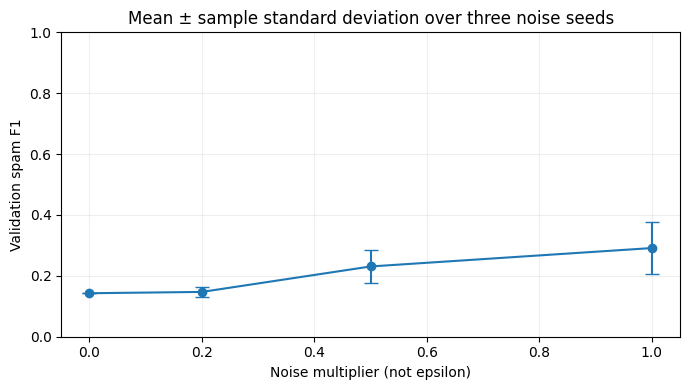

In [ ]:
sweep_rows = []
for multiplier in [0.0, 0.2, 0.5, 1.0]:
    for seed in [17, 23, 42]:
        result = train_federated(clip=CLIP_NORM, noise_multiplier=multiplier, seed=seed)
        sweep_rows.append({"noise_multiplier": multiplier, "seed": seed,
                           **evaluate(result["theta"], X_val, y_val)})
sweep = pd.DataFrame(sweep_rows)
sweep_summary = sweep.groupby("noise_multiplier").f1.agg(["mean", "std"])
print(sweep_summary.round(4).to_string())
plt.figure(figsize=(7, 4))
plt.errorbar(sweep_summary.index, sweep_summary["mean"], yerr=sweep_summary["std"], fmt="o-", capsize=5)
plt.xlabel("Noise multiplier (not epsilon)"); plt.ylabel("Validation spam F1")
plt.title("Mean ± sample standard deviation over three noise seeds")
plt.ylim(0,1); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

## 9. One final test evaluation
Select the best of the three original demonstration models using final-round **validation F1**, then evaluate that fixed model once on the test set. This chooses utility only; it does not impose a privacy requirement. A real application would first specify its privacy constraint and then optimize utility within it.

The noise sweep is exploratory and is not used to pick a lucky random seed or change the test model.

In [ ]:
selected = summary.f1.idxmax()
model = results[selected]["theta"]
print("Selected by validation F1:", selected)
print("Final test metrics:", {k: round(v, 4) for k, v in evaluate(model, X_test, y_test).items()})
pred = (expit(X_test @ model[:-1] + model[-1]) >= 0.5).astype(int)
print("Confusion matrix: rows=true, columns=predicted; order=[ham, spam]")
print(confusion_matrix(y_test, pred, labels=[0,1]))

Selected by validation F1: FedAvg
Final test metrics: {'f1': 0.7059, 'precision': 0.9474, 'recall': 0.5625, 'accuracy': 0.9419}
Confusion matrix: rows=true, columns=predicted; order=[ham, spam]
[[900   4]
 [ 56  72]]


## Instructor note: interpreting the default run
In the local CPU validation run, final validation spam F1 was approximately 0.764 for FedAvg, 0.143 for clipped FedAvg, and 0.255 for clipping plus noise (seed 42). Exact values can vary with software versions. These are observed results, not expected assertions in the code.

The deliberately restrictive C = 0.30 is a stress-test setting, not a recommended deployment value. Under label heterogeneity, clipping can change the relative influence of clients: a client with a strong spam-directed update may be truncated more than another client. Examine recall and the clipping diagnostics before attributing the effect simply to slower training.

In this run, modest noise sometimes improves F1 relative to the strongly clipped baseline. This does not prove that noise improves learning in general, or establish privacy. It illustrates why the class should report measured outcomes, repeat experiments, and investigate interactions among clipping, heterogeneity, and the classification threshold. No settings were changed to force a monotonically decreasing curve.

The full notebook executed successfully in approximately 8 seconds in the local test environment using cached data; Colab timing and initial download time will vary. It has not been executed inside the Colab service itself.


## 10. Student tasks and discussion
1. Explain why clipping must include the intercept as well as feature weights.
2. Change C to 0.1 or 1.0. Before running, predict changes in the clipping fraction and the per-coordinate noise standard deviation. Use validation data for the comparison.
3. Why can a small coordinate-wise noise standard deviation produce a large total noise norm in a high-dimensional model?
4. Replace equal client weighting with sample weighting. Explain how the objective and the sensitivity argument would change before claiming any privacy bound.
5. Which information can the server still observe? Which part would secure aggregation hide? Would that alone protect the final model?
6. Explain why the reported noise multiplier cannot be labeled epsilon.
7. For a research extension, repeat the full experiment over multiple partition seeds, state the client-adjacency definition, and use a validated privacy accountant. Do not infer a privacy guarantee from a reduction in F1.

**Submission:** one comparison table, the clipping diagnostic plot, and a short explanation connecting the mechanism to the observed results. Keep any further tuning on validation data; do not repeatedly tune against the test set.

### References and attribution
- Almeida, T. & Hidalgo, J. (2011). *SMS Spam Collection*. UCI Machine Learning Repository. [Dataset and license](https://archive.ics.uci.edu/dataset/228/sms+spam+collection), [DOI](https://doi.org/10.24432/C5CC84). CC BY 4.0. This notebook normalizes, deduplicates, splits, and synthetically partitions the data.
- Week 9 lecture: privacy threat models, differential privacy, secure aggregation, and privacy–utility trade-offs.

**Interpretation boundary:** this notebook demonstrates mechanisms on public data. It does not implement an attack, secure aggregation, a privacy accountant, or a production privacy system.